# Stories Coffee: Bundle Offers That Stay Profitable

**Question:** which two-item bundles should Stories offer, when and where, and at what discount, so that the offer adds gross profit instead of just giving away margin?

**Why it matters:** a bundle discount is paid on every bundle sold, including to customers who would have bought both items anyway. It only pays off if enough customers *upgrade* from one item to two. This notebook computes how many upgrades each bundle needs, from the price and cost data, and turns that into a pilot Stories can run.

Throughout, **observed facts** (computed from the data) are kept separate from **assumptions** (marked *Assumption*) and **estimates** (marked *Estimate*).

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import norm

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
# Repository layout: run from the repo root or notebooks/; data comes from STORIES_DATA or data/
ROOT = Path.cwd()
if not (ROOT / "reports").exists(): ROOT = ROOT.parent
DATA = Path(os.environ.get("STORIES_DATA", ROOT / "data" / "stories_transactions.csv"))
FIG = ROOT / "figures" / "bundle_offers"; FIG.mkdir(parents=True, exist_ok=True)

# One fixed colour per branch, same as 01_eda.ipynb
BRANCH_COLORS = {"Harbour": "#2a78d6", "Garden": "#eb6834", "Uptown": "#1baf7a"}
BRANCHES = list(BRANCH_COLORS)
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 11, "axes.titlelocation": "left",
    "font.size": 9, "legend.frameon": False, "lines.linewidth": 2,
})
def save(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight", dpi=150)

## 1. Load the data

Same cleaning as `01_eda.ipynb`: exact duplicate rows are removed. Time is split in two halves so that every choice made on the first half (Jan to Mar) is checked on the second half (Apr to Jun).

In [2]:
raw = pd.read_csv(DATA, dtype={"Customer ID": "string"})
raw = raw.rename(columns={
    "Transaction ID": "txn", "Date": "date", "Time": "time", "Branch": "branch",
    "Customer ID": "cust", "Order Type": "order_type", "Product": "product",
    "Category": "category", "Quantity": "qty", "Unit Price (USD)": "price",
    "Discount Rate": "disc", "Unit Cost (USD)": "cost",
    "Line Revenue (USD)": "rev", "Line Gross Profit (USD)": "gp"})
raw = raw[~raw.duplicated()].copy()
raw["ts"] = pd.to_datetime(raw["date"] + " " + raw["time"])
raw["date"] = pd.to_datetime(raw["date"])
raw["hour"] = raw.ts.dt.hour

SPLIT = pd.Timestamp("2026-04-01")
raw["half"] = np.where(raw.date < SPLIT, "train (Jan-Mar)", "test (Apr-Jun)")

txn = raw.groupby("txn").agg(branch=("branch", "first"), date=("date", "first"), hour=("hour", "first"),
                             half=("half", "first"), lines=("product", "size"),
                             rev=("rev", "sum"), gp=("gp", "sum"))
txn["cat_pair"] = raw.groupby("txn").category.apply(lambda s: tuple(sorted(s)))
txn["prod_pair"] = raw.groupby("txn")["product"].apply(lambda s: tuple(sorted(s)))
is_train = txn.half.str.startswith("train")

print("line items:", len(raw), "| transactions:", len(txn))
print("lines per transaction:", txn.lines.value_counts(normalize=True).sort_index().round(3).to_dict())
print("gross margin:", round(txn.gp.sum() / txn.rev.sum(), 3), "| average ticket: $", round(txn.rev.mean(), 2))
print("transactions with any discount:", round((raw.groupby("txn").disc.max() > 0).mean(), 3),
      "| discount levels:", sorted(raw.disc.unique()))

line items: 51045 | transactions: 33887
lines per transaction: {1: 0.538, 2: 0.417, 3: 0.045}
gross margin: 0.587 | average ticket: $ 9.01
transactions with any discount: 0.096 | discount levels: [np.float64(0.0), np.float64(0.1), np.float64(0.15)]


**Observed:** 54% of transactions are a single item, 42% have two lines and only 4.5% have three. So the natural bundle is **two items**; letting a model choose the bundle size would fit something the data barely shows. Discounts exist only at 10% and 15% and were not assigned at random, so the data **cannot measure how customers react to an offer**. That is the main limit of this notebook and the reason it ends in a pilot (section 6).

## 2. Which items really sell together?

Take baskets with exactly two lines. If customers chose the two items independently, a pair (A, B) would appear `N x 2 x share(A) x share(B)` times (`N x share(A)^2` when A = B). **Lift** is observed / expected: above 1 means the items go together more than chance.

To avoid picking pairs that look good by luck, pairs are **chosen on Jan to Mar** and **checked on Apr to Jun**.

In [3]:
def pair_lift(t, col):
    two = t[t.lines == 2][col]
    n = len(two)
    share = two.explode().value_counts() / (2 * n)
    obs = two.value_counts()
    exp = pd.Series([n * share[a] * share[b] * (1 if a == b else 2) for a, b in obs.index], index=obs.index)
    return pd.DataFrame({"obs": obs, "exp": exp, "lift": obs / exp})

def train_test(col, min_obs):
    out = pair_lift(txn[is_train], col).join(pair_lift(txn[~is_train], col), lsuffix="_train", rsuffix="_test", how="inner")
    return out[out.obs_train >= min_obs]

prod_pairs = train_test("prod_pair", 30)
print("product pairs with at least 30 two-item baskets in Jan-Mar:", len(prod_pairs), "of",
      txn[txn.lines == 2].prod_pair.nunique(), "pairs seen")
prod_pairs.sort_values("lift_train", ascending=False).round(2)

product pairs with at least 30 two-item baskets in Jan-Mar: 5 of 1001 pairs seen


,obs_train,exp_train,lift_train,obs_test,exp_test,lift_test
prod_pair,,,,,,
"(Iced Matcha, Pistachio Cookie)",34,14.93,2.28,35,16.95,2.07
"(Chocolate Croissant, Iced Matcha)",35,16.15,2.17,39,20.17,1.93
"(Chocolate Cookie, Iced Matcha)",40,18.82,2.12,37,21.45,1.72
"(Butter Croissant, Classic Matcha)",35,19.70,1.78,50,25.45,1.97
"(Butter Croissant, Iced Matcha)",37,23.89,1.55,53,28.03,1.89


**Observed:** with 45 products, specific product pairs are too rare to judge: only a handful reach 30 baskets in three months. The ones that do are all *a pastry or cookie with a matcha drink*. So bundles are defined at **category level** ("any bakery item + any matcha or tea drink"), where there is enough data.

In [4]:
cat_pairs = train_test("cat_pair", 30)
print("category pairs with at least 30 two-item baskets in Jan-Mar:", len(cat_pairs))
print("correlation of lift, Jan-Mar vs Apr-Jun:", round(cat_pairs.lift_train.corr(cat_pairs.lift_test), 2))
cat_pairs.sort_values("lift_train", ascending=False).head(10).round(2)

category pairs with at least 30 two-item baskets in Jan-Mar: 39
correlation of lift, Jan-Mar vs Apr-Jun: 0.9


,obs_train,exp_train,lift_train,obs_test,exp_test,lift_test
cat_pair,,,,,,
"(Cold Drinks, Meals)",76,36.89,2.06,87,49.98,1.74
"(Cold Drinks, Sandwiches)",178,93.63,1.90,254,120.65,2.11
"(Bakery, Matcha & Tea)",747,420.51,1.78,943,534.33,1.76
"(Breakfast, Sandwiches)",56,40.46,1.38,48,52.45,0.92
"(Bakery, Hot Coffee)",559,434.38,1.29,742,577.09,1.29
"(Bakery, Cold Coffee)",452,363.30,1.24,619,483.19,1.28
"(Breakfast, Cold Drinks)",70,56.63,1.24,65,68.19,0.95
"(Cold Coffee, Desserts)",154,128.50,1.20,209,171.37,1.22
"(Breakfast, Desserts)",50,42.65,1.17,72,53.87,1.34


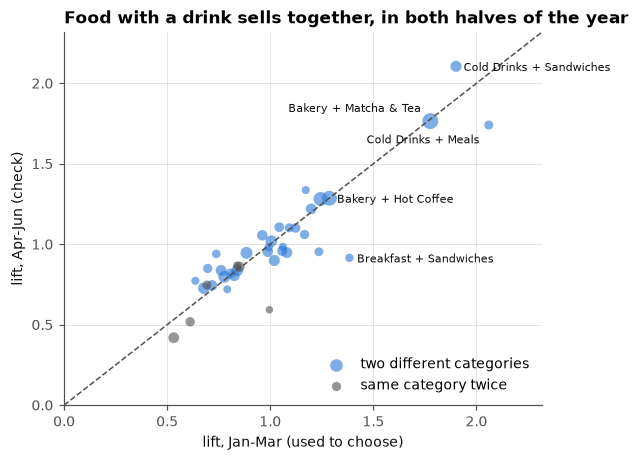

In [5]:
fig, ax = plt.subplots(figsize=(5.6, 4.4))
same = np.array([a == b for a, b in cat_pairs.index])
ax.scatter(cat_pairs.lift_train[~same], cat_pairs.lift_test[~same], s=np.sqrt(cat_pairs.obs_train[~same]) * 4,
           color="#2a78d6", alpha=0.6, lw=0, label="two different categories")
ax.scatter(cat_pairs.lift_train[same], cat_pairs.lift_test[same], s=np.sqrt(cat_pairs.obs_train[same]) * 4,
           color=MUTED, alpha=0.6, lw=0, label="same category twice")
lim = [0, max(cat_pairs.lift_train.max(), cat_pairs.lift_test.max()) * 1.1]
ax.plot(lim, lim, color=MUTED, lw=1, ls="--")
LEFT = {("Bakery", "Matcha & Tea"), ("Cold Drinks", "Meals")}  # label these on the left so they do not collide
for (a, b), r in cat_pairs[cat_pairs.lift_train >= 1.25].iterrows():
    left = (a, b) in LEFT
    ax.annotate(f"{a} + {b}", (r.lift_train, r.lift_test), fontsize=7, color=INK, ha="right" if left else "left",
                xytext=(-6, 6 if (a, b) == ("Bakery", "Matcha & Tea") else -12) if left else (5, -3), textcoords="offset points")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("lift, Jan-Mar (used to choose)"); ax.set_ylabel("lift, Apr-Jun (check)")
ax.set_title("Food with a drink sells together, in both halves of the year")
ax.legend(loc="lower right"); save(fig, "05_pair_lift_train_test"); plt.show()

**Observed:** the lift pattern repeats in the half-year it was not chosen on. Food with a drink goes together (cold drinks with sandwiches or meals, bakery with matcha, tea or coffee). Two items from the same category go together *less* than chance.

### 2.1 Should bundles push slow sellers?

The plan's first idea was to add an item that sells poorly on its own. The question is whether slow sellers can afford a discount.

In [6]:
prod = raw.groupby("product").agg(category=("category", "first"), units=("qty", "sum"),
                                  rev=("rev", "sum"), gp=("gp", "sum"))
prod["gm"] = prod.gp / prod.rev
sz = raw.groupby("txn")["product"].transform("size")
prod["sold_alone"] = (sz == 1).groupby(raw["product"]).mean()
print("correlation of units sold with share sold alone:", round(prod.units.corr(prod.sold_alone), 2))
print("correlation of units sold with gross margin:  ", round(prod.units.corr(prod.gm), 2))
prod.sort_values("units").head(8).round(2)

correlation of units sold with share sold alone: 0.22
correlation of units sold with gross margin:   0.11


,category,units,rev,gp,gm,sold_alone
product,,,,,,
Soup of the Day,Meals,449,3259.49,1836.23,0.56,0.33
English Breakfast Tea,Matcha & Tea,473,1656.47,1354.71,0.82,0.30
Quinoa Bowl,Meals,502,5902.44,3090.36,0.52,0.28
Chicken Salad Bowl,Meals,552,6942.19,3413.95,0.49,0.28
Granola Yoghurt,Breakfast,575,4570.19,2407.69,0.53,0.40
Mint Tea,Matcha & Tea,631,2328.56,1881.53,0.81,0.34
Espresso,Hot Coffee,686,1837.70,1336.16,0.73,0.35
Tuna Sandwich,Sandwiches,720,6424.55,3430.10,0.53,0.31


**Observed:** slow sellers are not sold alone more often than popular items. The slowest are mostly meals and bowls at about 50% margin, among the lowest on the menu, so they have the least room for a discount. Tea is the exception (about 80% margin). **Decision:** choose bundles by co-purchase lift and margin, not by low sales.

## 3. Candidate bundles and their economics

**Rule (fixed before looking at profit):** a pair of two *different* categories qualifies if its lift is at least 1.2 in Jan to Mar *and* in Apr to Jun. Qualifying pairs are ranked by their number of two-item baskets in Apr to Jun, and we keep up to three, using no category twice.

Prices and costs differ by branch (Garden's unit costs are about 1.4x the others, see `01_eda.ipynb`), so bundle economics are per branch. A category's price and profit are the averages of what customers actually bought in that category at that branch in Apr to Jun, at list price.

In [7]:
qual = cat_pairs[np.array([a != b for a, b in cat_pairs.index]) & (cat_pairs.lift_train >= 1.2) & (cat_pairs.lift_test >= 1.2)]
qual = qual.sort_values("obs_test", ascending=False)
chosen, used = [], set()
for a, b in qual.index:
    if a not in used and b not in used:
        chosen.append((a, b)); used |= {a, b}
    if len(chosen) == 3: break
print("qualifying pairs:", [f"{a} + {b}" for a, b in qual.index])
print("chosen bundles:  ", [f"{a} + {b}" for a, b in chosen])

qualifying pairs: ['Bakery + Matcha & Tea', 'Bakery + Hot Coffee', 'Bakery + Cold Coffee', 'Cold Drinks + Sandwiches', 'Cold Drinks + Meals']
chosen bundles:   ['Bakery + Matcha & Tea', 'Cold Drinks + Sandwiches']


In [8]:
test_lines = raw[~raw.half.str.startswith("train")]
unit = (test_lines.assign(list_rev=test_lines.qty * test_lines.price, list_gp=test_lines.qty * (test_lines.price - test_lines.cost))
        .groupby(["branch", "category"])[["qty", "list_rev", "list_gp"]].sum())
unit["price"], unit["gp"] = unit.list_rev / unit.qty, unit.list_gp / unit.qty
cat_units = raw.groupby("category").qty.sum()
rows = []
for a, b in chosen:
    anchor, partner = (a, b) if cat_units[a] >= cat_units[b] else (b, a)
    for br in BRANCHES:
        P = unit.loc[(br, anchor), "price"] + unit.loc[(br, partner), "price"]
        G = unit.loc[(br, anchor), "gp"] + unit.loc[(br, partner), "gp"]
        rows.append(dict(bundle=f"{anchor} + {partner}", anchor=anchor, partner=partner, branch=br, price=P, gp=G,
                         gm=G / P, gp_anchor=unit.loc[(br, anchor), "gp"], gp_partner=unit.loc[(br, partner), "gp"]))
bun = pd.DataFrame(rows)
bun.round(2)

,bundle,anchor,partner,branch,price,gp,gm,gp_anchor,gp_partner
0,Bakery + Matcha & Tea,Bakery,Matcha & Tea,Harbour,10.81,7.18,0.66,2.82,4.36
1,Bakery + Matcha & Tea,Bakery,Matcha & Tea,Garden,10.30,5.11,0.50,1.99,3.12
2,Bakery + Matcha & Tea,Bakery,Matcha & Tea,Uptown,9.85,6.38,0.65,2.49,3.89
3,Cold Drinks + Sandwiches,Cold Drinks,Sandwiches,Harbour,14.44,8.62,0.60,2.78,5.84
4,Cold Drinks + Sandwiches,Cold Drinks,Sandwiches,Garden,13.85,5.54,0.40,2.10,3.44
5,Cold Drinks + Sandwiches,Cold Drinks,Sandwiches,Uptown,13.12,7.59,0.58,2.43,5.16


### 3.1 Break-even: how many customers must upgrade?

For each bundle, at a discount `d` on the bundle price `P`:

- Every customer who **already** buys both items now pays `d x P` less. That is pure cost. (*Assumption, worst case:* all of them take the offer.)
- A customer who would have bought **only the anchor** (or only the partner) and now buys the bundle adds the bundle profit after discount minus the profit of the single item they would have bought.

Counting baskets in Apr to Jun gives the size of each group. The **break-even take-up** is the share of single-item buyers who must upgrade for the gains to cover the cost. *Assumption:* the offer brings no new customers and does not replace other items in the basket. Both effects are left out on purpose; one would help and one would hurt.

In [9]:
test_tx = txn[~is_train]
months_test = test_tx.date.dt.to_period("M").nunique()
basket_cats = test_tx.cat_pair.map(set)

def pools(mask, a, b):
    bc = basket_cats[mask]
    has_a, has_b = bc.map(lambda s: a in s), bc.map(lambda s: b in s)
    return pd.Series({"both": (has_a & has_b).sum(), "a_only": (has_a & ~has_b).sum(), "b_only": (~has_a & has_b).sum()})

def economics(r, p, d):
    cost = p.both * d * r.price
    upside = p.a_only * (r.gp - d * r.price - r.gp_anchor) + p.b_only * (r.gp - d * r.price - r.gp_partner)
    return cost, upside

DISCOUNTS = [0.05, 0.10, 0.15, 0.20]
be = []
for r in bun.itertuples():
    p = pools((test_tx.branch == r.branch).values, r.anchor, r.partner) / months_test
    for d in DISCOUNTS:
        cost, upside = economics(r, p, d)
        be.append(dict(bundle=r.bundle, branch=r.branch, discount=d, both_per_month=p.both,
                       singles_per_month=p.a_only + p.b_only, discount_cost_per_month=cost,
                       gain_per_anchor_upgrade=r.gp - d * r.price - r.gp_anchor,
                       breakeven_takeup=cost / upside if upside > 0 else np.inf))
be = pd.DataFrame(be)
be.pivot_table(index=["bundle", "branch"], columns="discount", values="breakeven_takeup").round(3)

discount                           0.05   0.10   0.15   0.20
bundle                   branch                             
Bakery + Matcha & Tea    Garden   0.035  0.092  0.200  0.489
                         Harbour  0.023  0.056  0.104  0.185
                         Uptown   0.023  0.056  0.105  0.190
Cold Drinks + Sandwiches Garden   0.019  0.054  0.148  1.145
                         Harbour  0.013  0.032  0.062  0.117
                         Uptown   0.018  0.045  0.091  0.187

In [10]:
be[be.discount == 0.10].drop(columns="discount").round(2)

,bundle,branch,both_per_month,singles_per_month,discount_cost_per_month,gain_per_anchor_upgrade,breakeven_takeup
1,Bakery + Matcha & Tea,Harbour,181.00,1295.33,195.60,3.27,0.06
5,Bakery + Matcha & Tea,Garden,123.33,841.67,126.98,2.09,0.09
9,Bakery + Matcha & Tea,Uptown,64.67,482.67,63.69,2.90,0.06
13,Cold Drinks + Sandwiches,Harbour,47.00,656.00,67.85,4.40,0.03
17,Cold Drinks + Sandwiches,Garden,27.00,453.67,37.39,2.05,0.05
21,Cold Drinks + Sandwiches,Uptown,26.33,304.67,34.54,3.85,0.04


## 4. Where and when to offer it

The plan proposed fewer offers when sales are high. We use **hour and branch only**, not weekday: the weekday pattern in this dataset is dominated by a Tuesday spike that real Stories shops do not show (see README), so a weekday rule could be built on an artifact.

**Quiet hours** are each branch's six least busy hours in Apr to Jun. *Assumption:* those hours have spare staff and seating, so extra bundle orders cost only ingredients. The data has no labour or capacity information, so this cannot be checked here.

In [11]:
hourly = (test_tx.groupby(["branch", "hour"]).size() / test_tx.date.nunique()).rename("tx_per_day").reset_index()
hourly["quiet"] = hourly.groupby("branch").tx_per_day.rank(method="first") <= 6
quiet = hourly.set_index(["branch", "hour"]).quiet
for br in BRANCHES:
    print(f"{br}: quiet hours {hourly[(hourly.branch == br) & hourly.quiet].hour.tolist()}")
in_quiet = quiet.reindex(pd.MultiIndex.from_frame(test_tx[["branch", "hour"]])).values
print("share of Apr-Jun transactions in quiet hours:", round(in_quiet.mean(), 3))

Harbour: quiet hours [7, 8, 9, 10, 11, 12]
Garden: quiet hours [7, 8, 9, 10, 11, 12]
Uptown: quiet hours [7, 8, 9, 10, 11, 12]
share of Apr-Jun transactions in quiet hours: 0.229


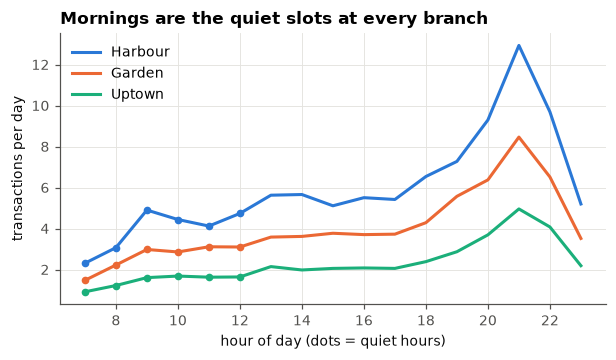

In [12]:
fig, ax = plt.subplots(figsize=(6.4, 3.2))
for br in BRANCHES:
    h = hourly[hourly.branch == br]
    ax.plot(h.hour, h.tx_per_day, color=BRANCH_COLORS[br], label=br)
    q = h[h.quiet]
    ax.scatter(q.hour, q.tx_per_day, color=BRANCH_COLORS[br], s=16, zorder=3)
ax.set_xlabel("hour of day (dots = quiet hours)"); ax.set_ylabel("transactions per day")
ax.set_title("Mornings are the quiet slots at every branch")
ax.legend(); save(fig, "06_hourly_traffic_by_branch"); plt.show()

In [13]:
# Break-even take-up when the offer runs only in quiet hours, 10% off
rows = []
for r in bun.itertuples():
    p = pools((test_tx.branch == r.branch).values & in_quiet, r.anchor, r.partner) / months_test
    cost, upside = economics(r, p, 0.10)
    rows.append(dict(bundle=r.bundle, branch=r.branch, both_per_month=p.both, singles_per_month=p.a_only + p.b_only,
                     share_already_both=p.both / (p.both + p.a_only + p.b_only), breakeven_takeup=cost / upside))
quiet_be = pd.DataFrame(rows)
all_day = be[be.discount == 0.10].set_index(["bundle", "branch"]).breakeven_takeup.rename("breakeven_all_day")
quiet_be.join(all_day, on=["bundle", "branch"]).round(3)

,bundle,branch,both_per_month,singles_per_month,share_already_both,breakeven_takeup,breakeven_all_day
0,Bakery + Matcha & Tea,Harbour,31.333,313.667,0.091,0.038,0.056
1,Bakery + Matcha & Tea,Garden,24.667,195.667,0.112,0.075,0.092
2,Bakery + Matcha & Tea,Uptown,8.667,111.333,0.072,0.030,0.056
3,Cold Drinks + Sandwiches,Harbour,12.000,144.000,0.077,0.038,0.032
4,Cold Drinks + Sandwiches,Garden,7.333,109.667,0.063,0.061,0.054
5,Cold Drinks + Sandwiches,Uptown,5.000,63.000,0.074,0.042,0.045


## 5. Forecast: expected profit with and without the offer

To show profit with and without bundles for a pilot month, we first need a forecast of normal traffic. Two forecasts are fitted on 1 Jan to 30 Apr and tested on 1 May to 30 Jun, data they did not see:

- **Baseline:** average daily transactions for the same branch and weekday in the training period.
- **Trend model:** the same weekday profile, scaled by each branch's growth trend (a straight line on log weekly transactions).

Error is the **weighted absolute percentage error (WAPE)** on daily transactions per branch.

In [14]:
day = txn.groupby(["branch", "date"]).size().rename("n").reset_index()
day["dow"] = day.date.dt.dayofweek
F_SPLIT = pd.Timestamp("2026-05-01")
trn, tst = day[day.date < F_SPLIT].copy(), day[day.date >= F_SPLIT].copy()
tst = tst.join(trn.groupby(["branch", "dow"]).n.mean().rename("base"), on=["branch", "dow"])

def fit_trend(d):
    # weekly growth from a straight line on log weekly totals, then a weekday profile around that trend
    t0 = d.date.min()
    w = d.assign(week=(d.date - t0).dt.days // 7).groupby("week").n.agg(["sum", "size"])
    w = w[w["size"] == 7]
    slope = np.polyfit(w.index, np.log(w["sum"]), 1)[0]
    wk = (d.date - t0).dt.days / 7
    prof = (d.n / np.exp(slope * wk)).groupby(d.dow).mean()
    return lambda dates: prof.reindex(dates.dt.dayofweek).values * np.exp(slope * (dates - t0).dt.days / 7), slope

for br in BRANCHES:
    f, slope = fit_trend(trn[trn.branch == br])
    m = tst.branch == br
    tst.loc[m, "trend"] = f(tst.loc[m, "date"])
    print(f"{br}: weekly growth {np.expm1(slope):.2%}")

def wape(y, f): return (y - f).abs().sum() / y.sum()
print("\nMay-Jun, daily transactions per branch      WAPE    bias")
print("  baseline (same branch-weekday average)  ", round(wape(tst.n, tst.base), 3), " ", round(tst.base.sum() / tst.n.sum() - 1, 3))
print("  trend model                             ", round(wape(tst.n, tst.trend), 3), " ", round(tst.trend.sum() / tst.n.sum() - 1, 3))

Harbour: weekly growth 1.91%
Garden: weekly growth 1.83%
Uptown: weekly growth 1.87%

May-Jun, daily transactions per branch      WAPE    bias
  baseline (same branch-weekday average)   0.222   -0.217
  trend model                              0.09   -0.007


**Observed:** the trend model beats the baseline clearly on unseen months. The baseline under-forecasts because traffic grows steadily (about 1.9% a week at every branch), which a plain average cannot follow.

Now the scenario for a **4-week pilot, 6 Jul to 2 Aug 2026**, with the offer at 10% off, either in quiet hours only or all day. The table by bundle and branch shows the all-day case. The trend model is refitted on all six months to project traffic. Bundle-related basket counts are scaled from Apr to Jun in proportion to projected traffic. Profit *with* the offer is shown for several take-up rates, because the take-up is unknown until it is tested.

In [15]:
PILOT_DATES = pd.Series(pd.date_range("2026-07-06", "2026-08-02"))
proj = {}
for br in BRANCHES:
    f, _ = fit_trend(day[day.branch == br])
    proj[br] = f(PILOT_DATES).sum()
scale = pd.Series(proj) / test_tx.groupby("branch").size()   # pilot weeks vs the whole Apr-Jun period

D, TAKEUP = 0.10, [0.0, 0.05, 0.10, 0.20, 0.30]
SCOPES = {"quiet hours": in_quiet, "all day": np.ones(len(test_tx), bool)}
sc = []
for scope, hours in SCOPES.items():
    for r in bun.itertuples():
        p = pools((test_tx.branch == r.branch).values & hours, r.anchor, r.partner) * scale[r.branch]
        cost, upside = economics(r, p, D)
        for u in TAKEUP:
            sc.append(dict(scope=scope, bundle=r.bundle, branch=r.branch, takeup=u, profit_change=u * upside - cost))
sc = pd.DataFrame(sc)
base_gp = pd.Series({br: test_tx[test_tx.branch == br].gp.sum() * scale[br] for br in BRANCHES})
print("Estimate: projected transactions in the 4 pilot weeks:", pd.Series(proj).round(0).to_dict())
print("Estimate: gross profit in those weeks without any offer ($):", base_gp.round(0).to_dict(), "| total", round(base_gp.sum()))
tot = sc.groupby(["scope", "takeup"]).profit_change.sum().unstack()
print("Estimate: total gross profit change, both bundles, all branches, 4 weeks ($):")
print(tot.round(0).to_string())
print("as % of baseline gross profit:")
print((tot / base_gp.sum() * 100).round(2).to_string())
q = sc[sc.scope == "all day"]
q.pivot_table(index=["bundle", "branch"], columns="takeup", values="profit_change", sort=False).round(0)

Estimate: projected transactions in the 4 pilot weeks: {'Harbour': 3421.0, 'Garden': 2290.0, 'Uptown': 1277.0}
Estimate: gross profit in those weeks without any offer ($): {'Harbour': 20533.0, 'Garden': 9535.0, 'Uptown': 6845.0} | total 36913
Estimate: total gross profit change, both bundles, all branches, 4 weeks ($):
takeup        0.00  0.05   0.10    0.20    0.30
scope                                          
all day     -578.0 -50.0  478.0  1534.0  2589.0
quiet hours -112.0  15.0  141.0   395.0   648.0
as % of baseline gross profit:
takeup       0.00  0.05  0.10  0.20  0.30
scope                                    
all day     -1.56 -0.14  1.29  4.15  7.01
quiet hours -0.30  0.04  0.38  1.07  1.76


takeup                             0.00  0.05   0.10   0.20   0.30
bundle                   branch                                   
Bakery + Matcha & Tea    Harbour -217.0 -22.0  172.0  561.0  950.0
                         Garden  -139.0 -63.0   13.0  165.0  317.0
                         Uptown   -68.0  -7.0   55.0  178.0  301.0
Cold Drinks + Sandwiches Harbour  -75.0  41.0  158.0  391.0  624.0
                         Garden   -41.0  -3.0   35.0  111.0  187.0
                         Uptown   -37.0   4.0   45.0  128.0  211.0

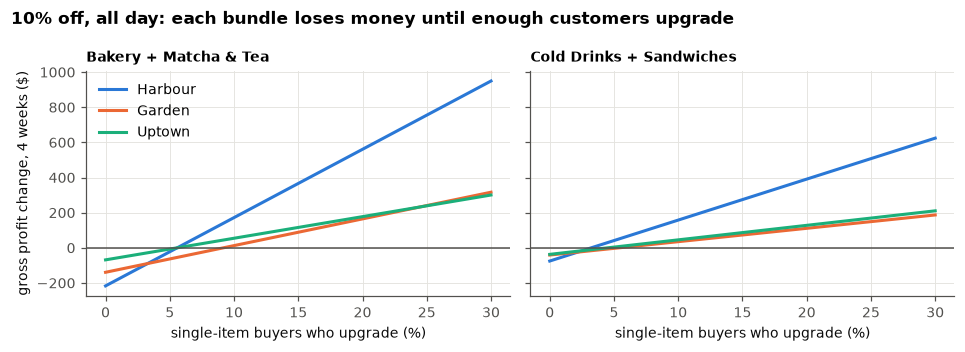

In [16]:
fig, axes = plt.subplots(1, len(chosen), figsize=(4.4 * len(chosen), 3.2), sharey=True)
for ax, (bname, g) in zip(axes, q.groupby("bundle", sort=False)):
    for br in BRANCHES:
        gb = g[g.branch == br]
        ax.plot(gb.takeup * 100, gb.profit_change, color=BRANCH_COLORS[br], label=br)
    ax.axhline(0, color=MUTED, lw=1)
    ax.set_title(bname, fontsize=9); ax.set_xlabel("single-item buyers who upgrade (%)")
axes[0].set_ylabel("gross profit change, 4 weeks ($)"); axes[0].legend()
fig.suptitle("10% off, all day: each bundle loses money until enough customers upgrade", x=0.01, ha="left",
             fontweight="bold", fontsize=11)
fig.tight_layout(); save(fig, "07_bundle_profit_vs_takeup"); plt.show()

## 6. A pilot Stories can run

The take-up rate cannot be learned from past data, so it has to be measured.

**Metric:** the *attach rate*, the share of baskets with the anchor category that also contain the partner category. If a share `u` of single buyers upgrade, the attach rate rises by about `u x anchor-only baskets / anchor baskets`. Comparing the offer weeks with the weeks just before (two-sided 5% test, 80% power) gives the **smallest take-up the test can reliably detect**.

Two designs are compared: the offer in quiet hours at one branch, and the offer all day at all three branches.

In [17]:
# A before/after comparison is only fair if the attach rate is stable without any offer
all_cats = txn.cat_pair.map(set)
month = txn.date.dt.to_period("M")
stab = {}
for bname in bun.bundle.unique():
    a, b = bun[bun.bundle == bname].iloc[0][["anchor", "partner"]]
    has_a, has_b = all_cats.map(lambda s: a in s), all_cats.map(lambda s: b in s)
    stab[bname] = (has_a & has_b).groupby(month).sum() / has_a.groupby(month).sum()
pd.DataFrame(stab).round(3)

,Bakery + Matcha & Tea,Cold Drinks + Sandwiches
date,,
2026-01,0.187,0.104
2026-02,0.190,0.106
2026-03,0.203,0.102
2026-04,0.194,0.093
2026-05,0.188,0.118
2026-06,0.175,0.110


**Observed:** without any offer, the attach rate moves by only 1 to 2 points from month to month, even though traffic grows by about half. That is smaller than the change the pilot is built to detect (about 3 points), so comparing offer weeks with the weeks just before is a fair test.

In [18]:
def detectable_takeup(mask, r_rows, weeks):
    out = []
    for r in r_rows.itertuples():
        p = pools(mask & (test_tx.branch == r.branch).values, r.anchor, r.partner) * scale[r.branch] * weeks / 4
        n_anchor = p.both + p.a_only
        p0 = p.both / n_anchor
        mde = (norm.ppf(0.975) + norm.ppf(0.8)) * np.sqrt(2 * p0 * (1 - p0) / n_anchor)
        out.append(dict(n_anchor=n_anchor, both=p.both, a_only=p.a_only))
    o = pd.DataFrame(out).sum()
    p0 = o.both / o.n_anchor
    mde = (norm.ppf(0.975) + norm.ppf(0.8)) * np.sqrt(2 * p0 * (1 - p0) / o.n_anchor)
    return o.n_anchor, p0, mde * o.n_anchor / o.a_only

rows = []
for bname in bun.bundle.unique():
    rb = bun[bun.bundle == bname]
    for design, mask, branches in [("Harbour, quiet hours", in_quiet, ["Harbour"]),
                                   ("all branches, all day", np.ones(len(test_tx), bool), BRANCHES)]:
        for weeks in [4, 8]:
            n, p0, u_min = detectable_takeup(mask, rb[rb.branch.isin(branches)], weeks)
            src = quiet_be if design.endswith("quiet hours") else be[be.discount == 0.10]
            be_u = src[(src.bundle == bname) & src.branch.isin(branches)].breakeven_takeup.max()
            rows.append(dict(bundle=bname, design=design, weeks=weeks, anchor_baskets=round(n),
                             attach_now=p0, smallest_detectable_takeup=u_min, breakeven_takeup_worst_branch=be_u))
pilot = pd.DataFrame(rows)
pilot.round(3)

,bundle,design,weeks,anchor_baskets,attach_now,smallest_detectable_takeup,breakeven_takeup_worst_branch
0,Bakery + Matcha & Tea,"Harbour, quiet hours",4,288,0.120,0.086,0.038
1,Bakery + Matcha & Tea,"Harbour, quiet hours",8,577,0.120,0.061,0.038
2,Bakery + Matcha & Tea,"all branches, all day",4,2192,0.185,0.040,0.092
3,Bakery + Matcha & Tea,"all branches, all day",8,4385,0.185,0.028,0.092
4,Cold Drinks + Sandwiches,"Harbour, quiet hours",4,110,0.121,0.141,0.038
5,Cold Drinks + Sandwiches,"Harbour, quiet hours",8,219,0.121,0.099,0.038
6,Cold Drinks + Sandwiches,"all branches, all day",4,1025,0.107,0.043,0.054
7,Cold Drinks + Sandwiches,"all branches, all day",8,2050,0.107,0.030,0.054


## 7. Recommendation

**Run a 4-week pilot of two bundles at 10% off, at all three branches, all day:**

1. **Any bakery item + any matcha or tea drink** (lift 1.78 in Jan to Mar, 1.76 in Apr to Jun).
2. **Any cold drink + any sandwich** (lift 1.90, then 2.11).

**Measured (from the data):**
- Five category pairs qualify, but with no category used twice only these two can be chosen. Food with a drink sells together; two drinks do not.
- At 10% off, an offer breaks even when **3 to 6% of single-item buyers upgrade** at Harbour and Uptown, and **5 to 9% at Garden**, whose higher unit costs leave less margin. At 15% off the required take-up roughly doubles. At 20% off the cold drink and sandwich bundle at Garden needs more than 100% take-up, so it can never pay.
- The trend forecast predicts daily traffic on unseen months with 9% error, against 22% for a plain weekday average.

**Estimated (depends on take-up, which is unknown):**

| Take-up of single buyers | 0% | 5% | 10% | 20% |
|---|---|---|---|---|
| Gross profit change, 4 weeks, all branches, all day | -$578 | -$50 | +$478 | +$1,534 |
| As % of projected gross profit ($36,913) | -1.6% | -0.1% | +1.3% | +4.2% |

At 10 to 20% take-up that is roughly **$6,000 to $20,000 a year** of extra gross profit, if traffic keeps its current trend. Offering only in quiet morning hours carries about a quarter of that value.

**Why this pilot design:** across all branches and all day, 4 weeks can detect a take-up of about 4%, below every branch's break-even. A quiet-hours test at one branch could only detect 9 to 14%, so it could not tell a profitable offer from a loss. The worst case, nobody upgrades, costs about $580 of gross profit (1.6% of the period), which caps the risk.

**Decision rule, set before the pilot:** keep a bundle at a branch only if its measured take-up beats that branch's break-even. Track average basket profit too, to catch customers swapping a more profitable item for the bundle. If evening service slows, restrict the offer to before 18:00.

**How this answers the original plan:** the number of bundles (2) comes from the qualifying rule, the bundle size (2 items) from the basket data, and the discount (10%) from the break-even table. Profit with and without the offer comes from the forecast plus take-up scenarios. The one input the data cannot provide, take-up, is what the pilot measures.

## 8. What could change this, and what we rejected

- **Synthetic data.** Transaction IDs start with `SYN-` and the brief says the IDs were replaced. If the basket structure was also simulated, the pair lifts describe the simulator, not Stories' customers. The pilot is designed to catch this: it measures attach rates in real stores.
- **No offer history.** The only discounts are 10% and 15% and they were not assigned at random, so customer response to a bundle is unknown. That is why profit is shown as scenarios and the recommendation is a test, not a rollout.
- **Costs are standard costs.** If `Unit Cost` leaves out waste or labour, true margins are lower and the break-even take-up is higher.
- **Capacity is assumed, not measured.** Offering in quiet hours only makes sense if staff and seats are free then. The data has no labour information.
- **Substitution is left out.** A customer might take the bundle instead of a different, more profitable item. A pilot should track average basket profit, not only the attach rate.
- **Tuesday.** The weekday pattern is excluded from targeting because the Tuesday spike may be an artifact. The forecast still uses weekday profiles, so its daily numbers inherit that pattern; the 4-week totals are not affected much.
- **Rejected: a model that chooses the number of bundles and items per bundle.** Baskets almost never exceed two products, and nothing in the data measures menu fatigue or bundle uptake, so those would be guesses presented as model outputs. We fixed 2-item bundles and at most 3 bundles as a business choice.
- **Rejected: pushing slow sellers.** The slowest items carry some of the lowest margins (about 50%), so they are the most expensive to discount.
- **Rejected: weekday targeting.** See the Tuesday point above.